In [1]:
# Run in terminal:
#uv init
#uv add --dev ipykernel jupyter
#uv sync

In [2]:
!uv pip install -q osmnx networkx "geopandas[all]" pyrosm lonboard

In [3]:
import osmnx as ox
import geopandas as gpd
import networkx as nx
import matplotlib.pyplot as plt
import lonboard as lb
from pyrosm import OSM
from pathlib import Path

# Suppress warnings to keep output clean
import warnings
warnings.filterwarnings("ignore")

In [4]:
pbf_path = '../data/raw/norcal-261025.osm.pbf'

bay_area_bbox = (-122.673340,37.169072,-121.464844,38.272689)

osm = OSM(pbf_path, bounding_box=bay_area_bbox)

# Extract walking network
walk_nodes, walk_edges = osm.get_network(
    network_type='walk',
    nodes=True,
)

# Build walking graph
G_walk = osm.to_graph(
    walk_nodes,
    walk_edges,
    graph_type="networkx"
)

# Extract driving network
drive_nodes, drive_edges = osm.get_network(
    network_type='drive',
    nodes=True,
)

# Build driving graph
G_drive = osm.to_graph(
    drive_nodes,
    drive_edges,
    graph_type="networkx"
)


print(f"Nodes: {G_walk.number_of_nodes():,}")
print(f"Edges: {G_walk.number_of_edges():,}")
print(f"Got the walking network for the Bay Area!")

print(f"Nodes: {G_drive.number_of_nodes():,}")
print(f"Edges: {G_drive.number_of_edges():,}")
print(f"Got the driving network for the Bay Area!")


Reading norcal-261025.osm.pbf: loading the result:   0%|          | 00:02<?

Building the NetworkX graph: directing the edges:   0%|          | 00:02<?

Reading norcal-261025.osm.pbf: loading the result:   0%|          | 00:08<?

Building the NetworkX graph: keeping the largest connected part:   2%|1         | 00:02<01:44

Nodes: 749,473
Edges: 2,073,918
Got the walking network for the Bay Area!
Nodes: 177,785
Edges: 432,512
Got the driving network for the Bay Area!


In [5]:
#walk_graph_path = Path("../data/raw/bay_area_walk.graphml")
#drive_graph_path = Path("../data/raw/bay_area_drive.graphml")

#ox.io.save_graphml(G_walk, filepath=walk_graph_path)
#ox.io.save_graphml(G_drive, filepath=drive_graph_path)

#print(f"Saved walking network to: {walk_graph_path.resolve()}")
#print(f"Saved driving network to: {drive_graph_path.resolve()}")

In [6]:
# Project graphs to local UTM zones
G_walk_proj = ox.project_graph(G_walk)
G_drive_proj = ox.project_graph(G_drive)

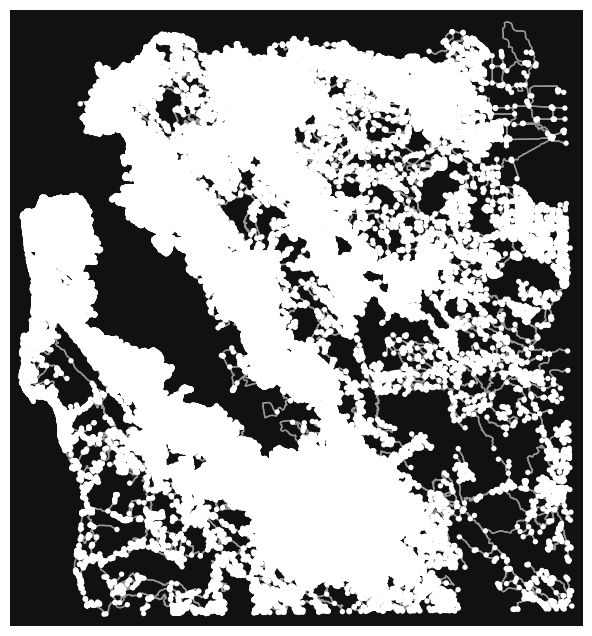

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>)

In [8]:
ox.plot.plot_graph(G_walk_proj)

In [7]:
walk_stats = ox.basic_stats(G_walk_proj, area=area_m2, clean_int_tol=15)
drive_stats = ox.basic_stats(G_drive_proj, area=area_m2, clean_int_tol=15)

print("WALK NETWORK STATS")
print(f"  Nodes (intersections): {walk_stats['n']:,}")
print(f"  Edges (street segments): {walk_stats['m']:,}")
print(f"  Avg connections per intersection: {walk_stats['k_avg']:.1f}")
print(f"  Total street length: {walk_stats['edge_length_total']/1000:.0f} km")
print(f"  Avg edge length: {walk_stats['edge_length_avg']:.0f} m")
print(f"  Street density: {walk_stats['street_density_km']:.0f} m/km²")
print(f"  Circuity: {walk_stats['circuity_avg']:.2f}")
print("    (1.0 = perfectly straight routes, higher = more winding)")

print("\nDRIVE NETWORK STATS")
print(f"  Nodes (intersections): {drive_stats['n']:,}")
print(f"  Edges (street segments): {drive_stats['m']:,}")
print(f"  Avg connections per intersection: {drive_stats['k_avg']:.1f}")
print(f"  Total street length: {drive_stats['edge_length_total']/1000:.0f} km")
print(f"  Avg edge length: {drive_stats['edge_length_avg']:.0f} m")
print(f"  Street density: {drive_stats['street_density_km']:.0f} m/km²")
print(f"  Circuity: {drive_stats['circuity_avg']:.2f}")
print("    (1.0 = perfectly straight routes, higher = more winding)")


NameError: name 'area_m2' is not defined

In [11]:
bart_stations_url = 'https://services3.arcgis.com/i2dkYWmb4wHvYPda/arcgis/rest/services/BART_Stations/FeatureServer/0'

bart_stations = gpd.read_file(
    f"{bart_stations_url}/query"
    "?where=1%3D1"
    "&outFields=*"
    "&returnGeometry=true"
    "&f=geojson"
)

gdf.to_file(
    "data/raw/bart_stations.geojson",
    driver="GeoJSON"
)